# Inteligencia Comercial: Unidad 3 - Actividad 1


**Consigna:**  
Basándose en la Actividad N°1 de la unidad temática II (DW), imaginen que tenemos que presentar los informes sobre las 4 preguntas que planteamos en esa actividad. ¿Cómo harían mas interesante y atractiva la presentación? 
Deben incluir ejemplos de gráficos (entre 2 y 3 gráficos son suficientes), para eso pueden utilizar datos ficticios. Es importante que además incluyan una breve descripción que explique los gráficos que se están visualizando, como si estuviesen "contando" la presentación a la gerencia de la empresa. Deben incluir algún insight y como lo contarían a la audiencia. 


**1-**  
La audiencia objetivo de la presentación consta de la gerencia general y/o la dirección del área de ventas. Se caracterizan por tener un perfil ejecutivo con fuerte enfoque en métricas cuantitativas (como volumen o total facturado), con una visión global y estratégica del negocio: los datos técnicos de la base de datos y las tablas crudas en general son irrelevantes.
La presentación tiene como objetivo demostrar las diferencias en el desempeño comercial entre las modalidades de venta ofrecidas por la organización y evidenciar el impacto y la dispersión del rendimiento de los vendedores para justificar decisiones de asignación de cuotas y fuerza de ventas.
Las preguntas de la actividad anterior eran:  
> *a.	“Deseo mostrar [la cantidad de vehículos vendidos] divididas [por mes, año, trimestre, producto, vendedores, equipo de venta, supervisor, sucursales, cliente, segmento cliente, modelo]" (dada por la consigna)*  
> *b.	Deseo mostrar [el importe total facturado] divididas por [mes, año, trimestre, modalidad de venta, modelo, categoría de vehículo, tipo de combustible, sucursal, equipo de venta, supervisor y vendedor].*  
> *c.	Deseo mostrar [el promedio de vehículos vendidos por vendedor] divididos por [mes, año, sucursal, equipo de venta, supervisor, modalidad de venta, modelo y categoría de vehículo].*  
> *d.	Deseo mostrar [el importe promedio de venta por vehículo] dividido por [mes, año, trimestre, modalidad de venta, modelo, categoría de vehículo, tipo de combustible, sucursal y vendedor].*  

Para dar un panorama global, se va a mostrar la **evolución trimestral de facturación y entregas por modalidad**. Consta de un gráfico de columnas agrupadas con 2 ejes. En el eje horizontal está la variable tiempo (trimestres 1 a 4), mientras que en el eje vertical se muestra la cantidad de vehículos vendidos. Cada barra tendrá una anotación en la cima con el importe vendido en dólares.
Se eligió usar un gráfico de columnas agrupadas para poder diferenciar la modalidad aplicando colores distintos a las barras y evitar la introducción de un segundo eje Y.


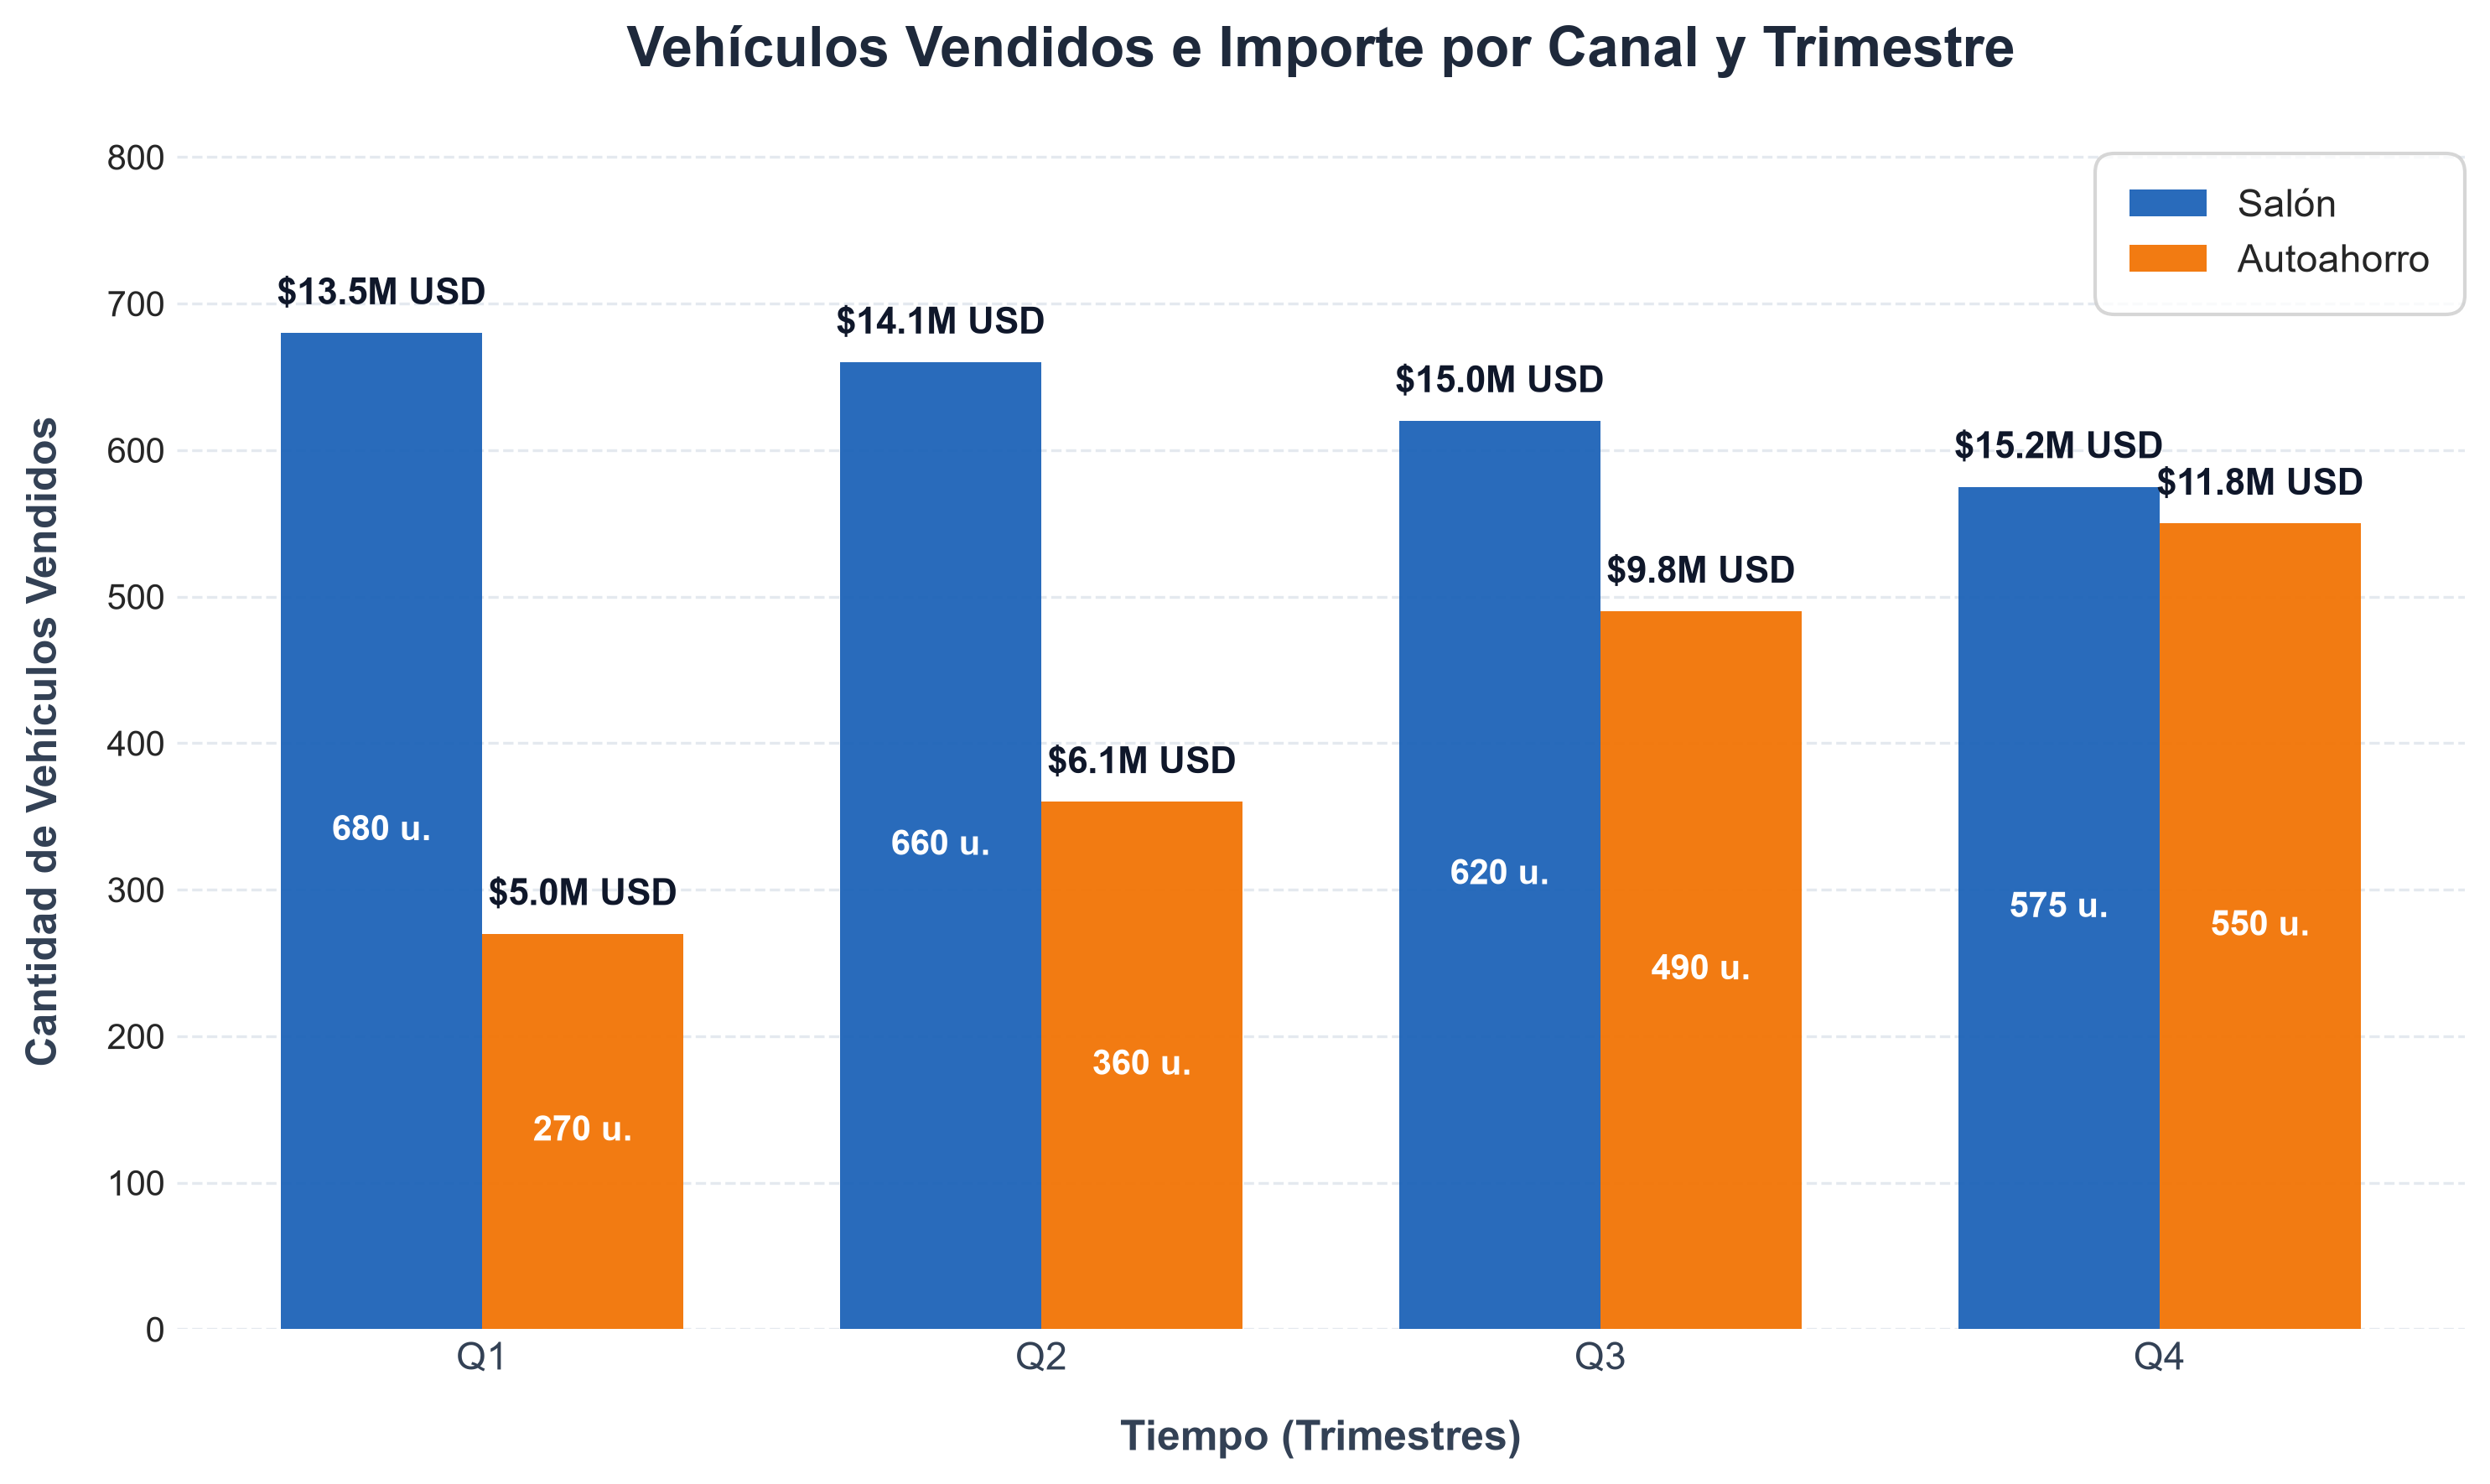

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Datos trimestrales
trimestres = ['Q1', 'Q2', 'Q3', 'Q4']
cant_salon = [680, 660, 620, 575]
monto_salon = [13.5, 14.1, 15.0, 15.2]

cant_autoahorro = [270, 360, 490, 550]
monto_autoahorro = [5.0, 6.1, 9.8, 11.8]

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

x = np.arange(len(trimestres))
width = 0.36

color_salon = '#1D63B8' # Azul
color_autoahorro = '#F27405' # Naranja

rects1 = ax.bar(x - width/2, cant_salon, width, label='Salón', color=color_salon, alpha=0.95, zorder=3)
rects2 = ax.bar(x + width/2, cant_autoahorro, width, label='Autoahorro', color=color_autoahorro, alpha=0.95, zorder=3)

ax.set_title('Vehículos Vendidos e Importe por Canal y Trimestre', fontsize=16, fontweight='bold', pad=25, color='#1e293b')
ax.set_xlabel('Tiempo (Trimestres)', fontsize=12, fontweight='bold', labelpad=12, color='#334155')
ax.set_ylabel('Cantidad de Vehículos Vendidos', fontsize=12, fontweight='bold', labelpad=12, color='#334155')
ax.set_xticks(x)
ax.set_xticklabels([f'{q}' for i, q in enumerate(trimestres)], fontsize=11, color='#334155')

max_val = max(max(cant_salon), max(cant_autoahorro))
ax.set_ylim(0, max_val * 1.18)

ax.yaxis.grid(True, linestyle='--', alpha=0.5, color='#cbd5e1', zorder=0)
ax.xaxis.grid(False)
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#94a3b8')

def add_labels(rects, montos):
    for rect, monto in zip(rects, montos):
        height = rect.get_height()
        ax.annotate(f'${monto:.1f}M USD',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 6),
                    textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=10.5, fontweight='bold',
                    color='#0f172a')
        ax.annotate(f'{height} u.',
                    xy=(rect.get_x() + rect.get_width() / 2, height / 2),
                    xytext=(0, 0),
                    textcoords='offset points',
                    ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white')

add_labels(rects1, monto_salon)
add_labels(rects2, monto_autoahorro)

legend = ax.legend(frameon=True, fontsize=11, loc='upper right')
legend.get_frame().set_boxstyle('round,pad=0.5')

plt.tight_layout()
plt.show()

Analizando el gráfico se puede notar un **gran contraste**: por un lado las ventas de Salón observan una tendencia a la baja de ventas físicas, aunque mantiene un volumen de facturación relativamente estable (13-14m usd). Esto puede ser debido a que vendieron modelos de gama más alta, con mayor equipamiento o aplicaron subas directas de precios en dólares que compensaron la baja en volumen físico. Por el otro lado, en las ventas de Autoahorro se muestra una tendencia alcista tanto en facturación como en volumen de ventas. **Prácticamente *el total del crecimiento genuino de los ingresos de la compañía** en el segundo semestre proviene de la expansión de este segmento. La conclusión a la que se puede llegar es que la venta en Salón actúa como ancla de flujo operativo, pero el canal de Autoahorro es el motor de captación y volumen de las concesionarias.  
Para el siguiente gráfico se muestra una **matriz de desempeño clasificados por categoría y tipo de combustible**. Es un diagrama de dispersión dividido en cuadrantes, siendo el cuadrante más deseado (más rentable) el de arriba a la derecha. En el eje X están las cantidades anuales vendidas y en el eje Y el importe promedio por vehículo vendido. Para simplificar el gráfico sólo se tomaron 4 puntos que corresponden al promedio general de cada categoría para que se pueda ver la correlación negativa de forma más clara.


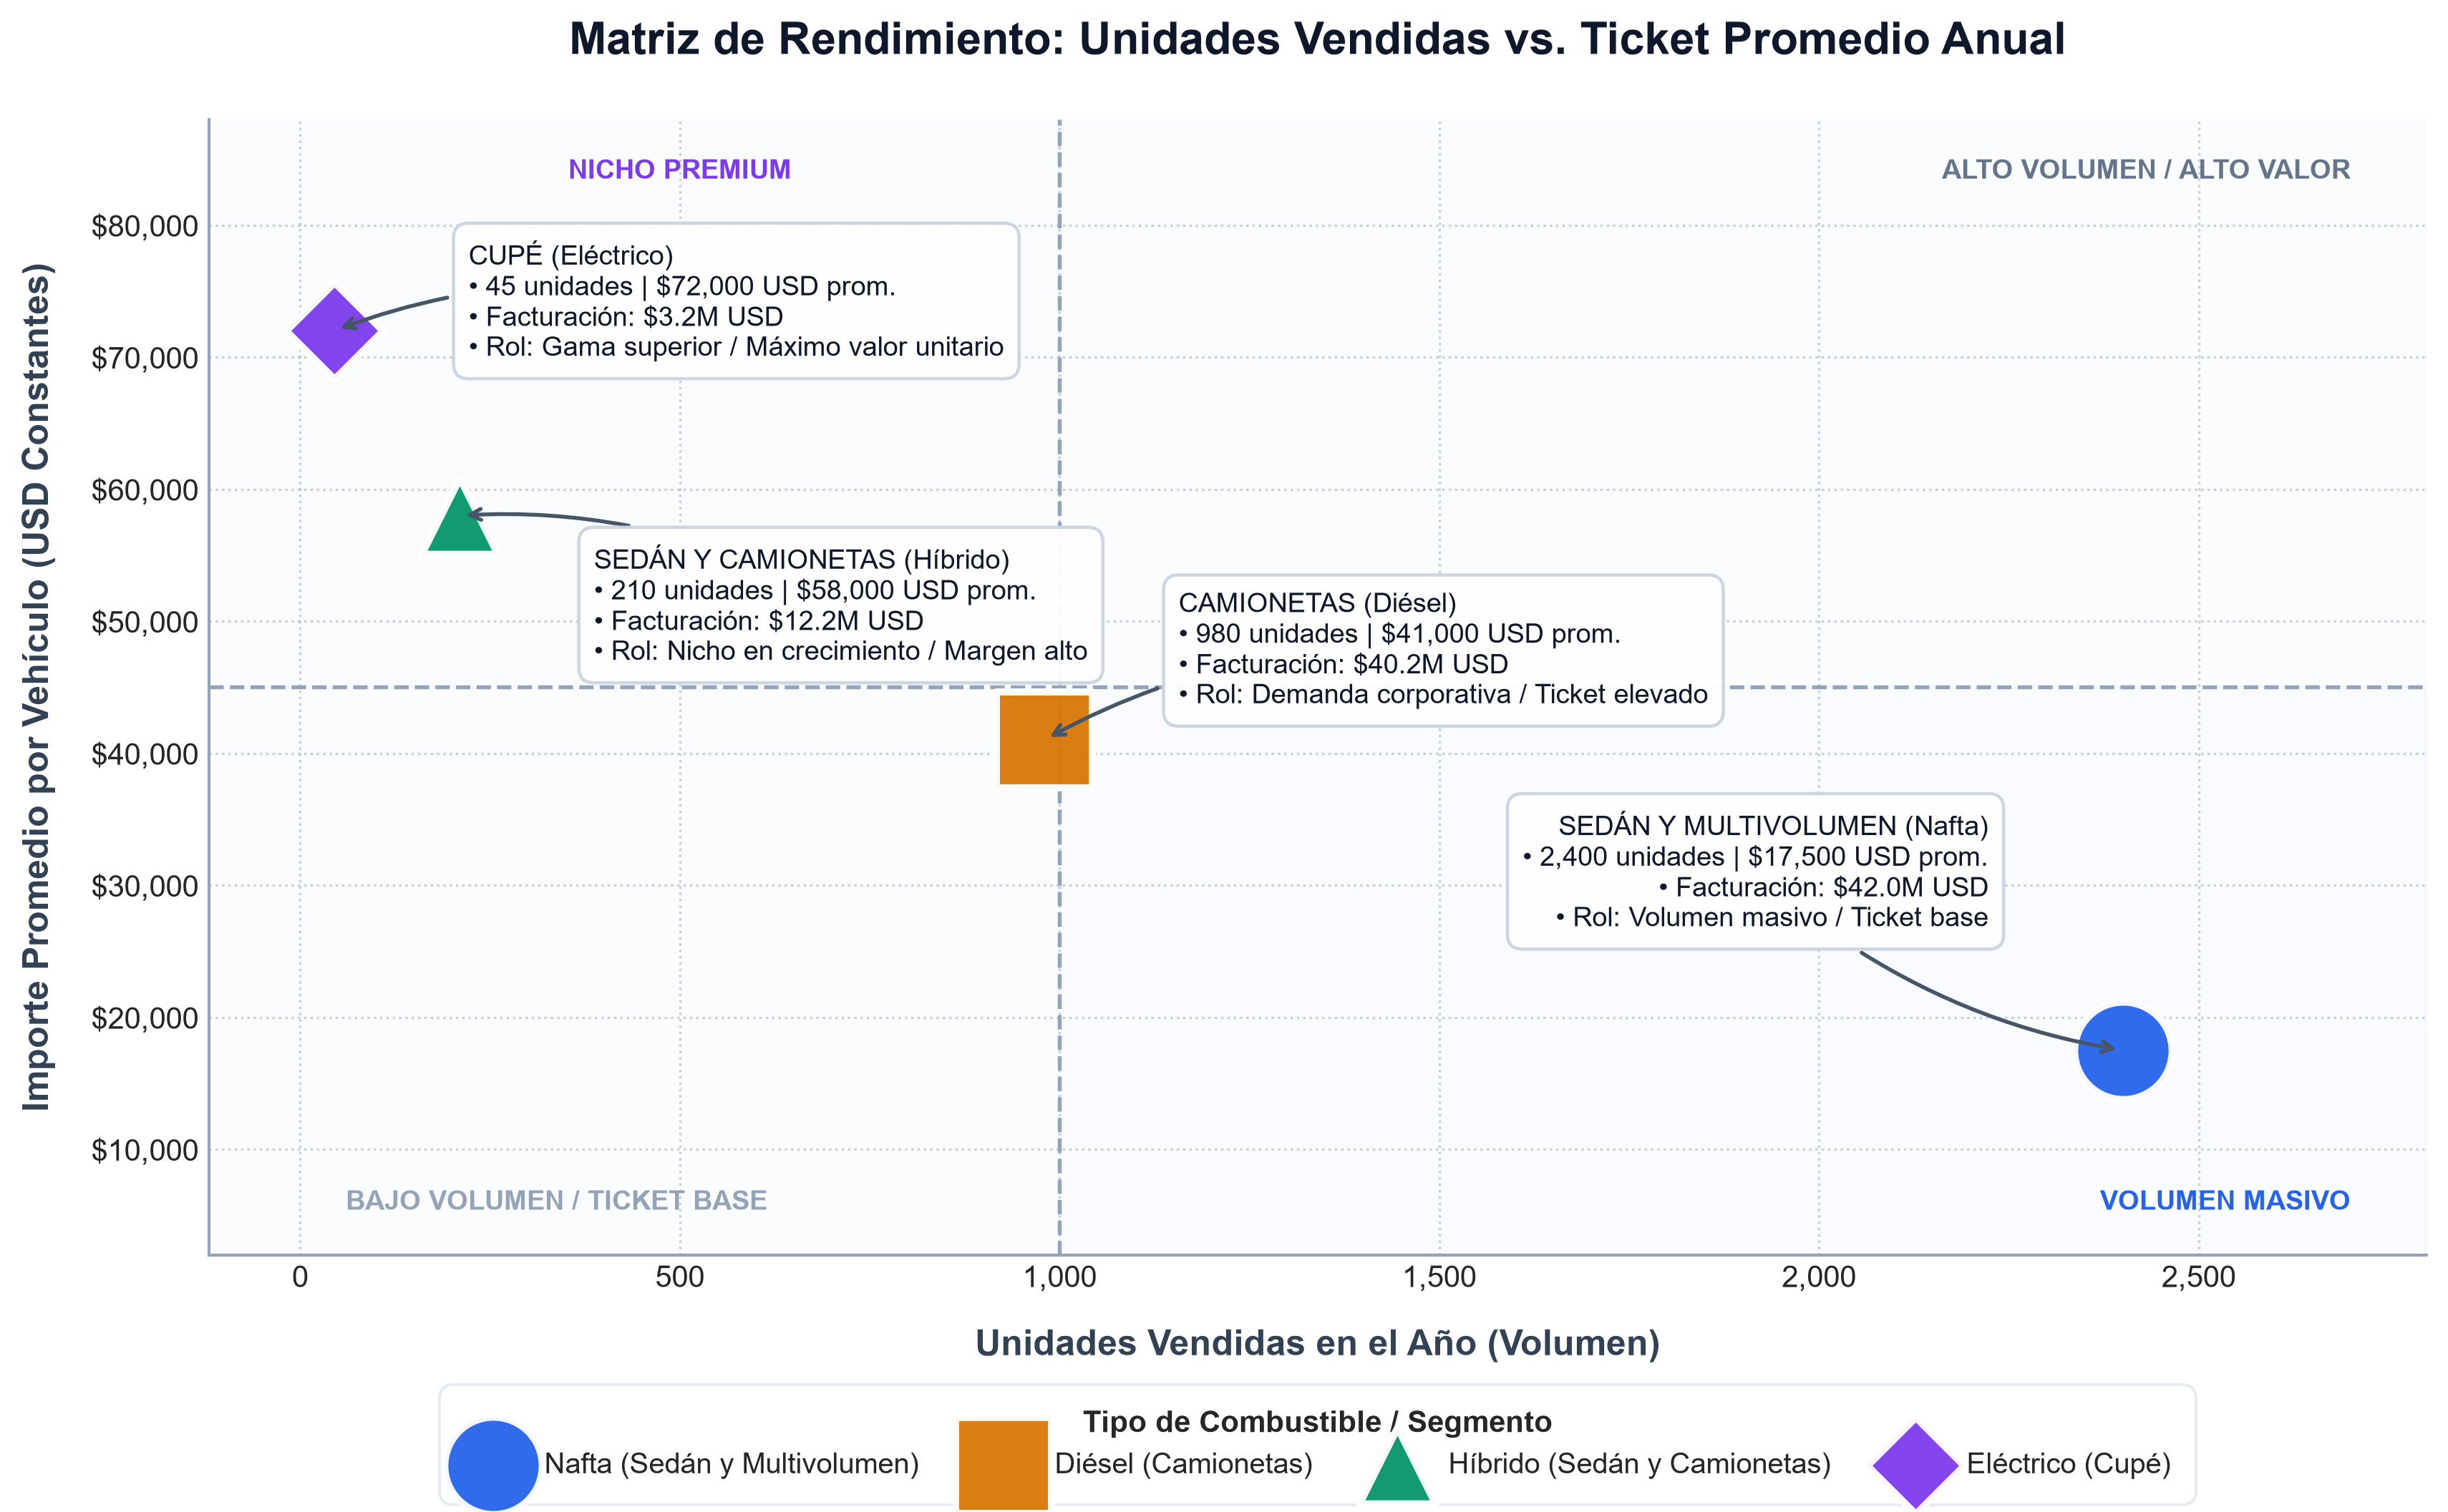

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

datos = [
    {
        'segmento': 'Sedán y Multivolumen',
        'combustible': 'Nafta',
        'unidades': 2400,
        'ticket': 17500,
        'rol': 'Volumen masivo / Ticket base',
        'color': '#2563EB',
        'marker': 'o',
        'ha': 'right',
        'offset_xy': (-45, 60)
    },
    {
        'segmento': 'Camionetas',
        'combustible': 'Diésel',
        'unidades': 980,
        'ticket': 41000,
        'rol': 'Demanda corporativa / Ticket elevado',
        'color': '#D97706',
        'marker': 's',
        'ha': 'left',
        'offset_xy': (45, 30)
    },
    {
        'segmento': 'Sedán y Camionetas',
        'combustible': 'Híbrido',
        'unidades': 210,
        'ticket': 58000,
        'rol': 'Nicho en crecimiento / Margen alto',
        'color': '#059669',
        'marker': '^',
        'ha': 'left',
        'offset_xy': (45, -30)
    },
    {
        'segmento': 'Cupé',
        'combustible': 'Eléctrico',
        'unidades': 45,
        'ticket': 72000,
        'rol': 'Gama superior / Máximo valor unitario',
        'color': '#7C3AED',
        'marker': 'D',
        'ha': 'left',
        'offset_xy': (45, 10)
    }
]

fig, ax = plt.subplots(figsize=(11.5, 7.2), dpi=300)

x_mid = 1000
y_mid = 45000

ax.axvline(x=x_mid, color='#94a3b8', linestyle='--', linewidth=1.3, zorder=1)
ax.axhline(y=y_mid, color='#94a3b8', linestyle='--', linewidth=1.3, zorder=1)

ax.fill_between([x_mid, 2800], y_mid, 88000, color='#f8fafc', alpha=0.5, zorder=0)
ax.fill_between([-120, x_mid], y_mid, 88000, color='#f1f5f9', alpha=0.35, zorder=0)
ax.fill_between([x_mid, 2800], 0, y_mid, color='#eff6ff', alpha=0.35, zorder=0)
ax.fill_between([-120, x_mid], 0, y_mid, color='#f8fafc', alpha=0.5, zorder=0)

ax.text(2700, 85000, 'ALTO VOLUMEN / ALTO VALOR', fontsize=9, fontweight='bold', color='#64748b', ha='right', va='top')
ax.text(500, 85000, 'NICHO PREMIUM', fontsize=9, fontweight='bold', color='#7c3aed', ha='center', va='top')
ax.text(2700, 5000, 'VOLUMEN MASIVO', fontsize=9, fontweight='bold', color='#2563eb', ha='right', va='bottom')
ax.text(60, 5000, 'BAJO VOLUMEN / TICKET BASE', fontsize=9, fontweight='bold', color='#94a3b8', ha='left', va='bottom')

for d in datos:
    facturacion_m = (d['unidades'] * d['ticket']) / 1_000_000
    size = 480 + (facturacion_m * 14)
    
    ax.scatter(d['unidades'], d['ticket'], 
               s=size, color=d['color'], marker=d['marker'],
               edgecolors='#ffffff', linewidth=2.4, zorder=4, alpha=0.95,
               label=f"{d['combustible']} ({d['segmento']})")
    
    texto = (
        f"{d['segmento'].upper()} ({d['combustible']})\n"
        f"• {d['unidades']:,} unidades | ${d['ticket']:,} USD prom.\n"
        f"• Facturación: ${facturacion_m:.1f}M USD\n"
        f"• Rol: {d['rol']}"
    )
    
    ax.annotate(
        texto,
        xy=(d['unidades'], d['ticket']),
        xytext=d['offset_xy'],
        textcoords="offset points",
        ha=d['ha'],
        va='center',
        fontsize=9.2,
        color='#0f172a',
        bbox=dict(boxstyle='round,pad=0.55', facecolor='#ffffff', edgecolor='#cbd5e1', alpha=0.96, linewidth=1.1),
        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.15', color='#475569', lw=1.3),
        zorder=5
    )

ax.set_title('Matriz de Rendimiento: Unidades Vendidas vs. Ticket Promedio Anual', fontsize=15, fontweight='bold', pad=22, color='#0f172a')
ax.set_xlabel('Unidades Vendidas en el Año (Volumen)', fontsize=12, fontweight='bold', labelpad=12, color='#334155')
ax.set_ylabel('Importe Promedio por Vehículo (USD Constantes)', fontsize=12, fontweight='bold', labelpad=12, color='#334155')

ax.set_xlim(-120, 2800)
ax.set_ylim(2000, 88000)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(True, linestyle=':', alpha=0.5, color='#94a3b8', zorder=0)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#94a3b8')
ax.spines['bottom'].set_color('#94a3b8')

legend = ax.legend(title='Tipo de Combustible / Segmento', 
                   loc='lower center', 
                   bbox_to_anchor=(0.5, -0.22),
                   ncol=4, 
                   frameon=True, 
                   facecolor='#ffffff', 
                   edgecolor='#e2e8f0', 
                   fontsize=9.5, 
                   title_fontsize=10)
legend.get_title().set_fontweight('bold')
legend.get_frame().set_boxstyle('round,pad=0.5')

plt.tight_layout()
plt.show()

Los sedanes nafteros aseguran la absorción de costos fijos y el volumen operativo, pero **el ingreso unitario lo sostienen las camionetas diésel** (en mayor medida) y la tecnología híbrida. Cada vehículo híbrido comercializado a un ticket de $58,000 USD aporta lo equivalente a más de tres sedanes convencionales, demostrando que diversificar el catálogo estabilizó la facturación anual.  
El gráfico muestra una correlación inversa perfecta entre grado de electrificación y volumen de ventas, lo que podría indicar que los vehículos electrificados aún se encuentran en fase de nicho / innovadores (early adopters). Además, no existe un producto actualmente que combine escala con ticket elevado. Una oportunidad/objetivo del negocio podría ser posicionar a las camionetas (Diésel o Híbridas) para que superen las 1,200 unidades anuales, conquistando este cuadrante ideal.  
Para el último gráfico se decidió usar un **diagrama de barras horizontales** para mostrar el promedio de unidades vendidas por vendedor, sucursal y localidad. Las sucursales se redujeron a 6 por una cuestión de disponibilidad de datos. En el eje X se observan la cantidad de unidades vendidas por empleado en promedio, mientras que en el eje Y se muestran las sucursales y su correspondiente localidad con las ventas discriminadas por modalidad.

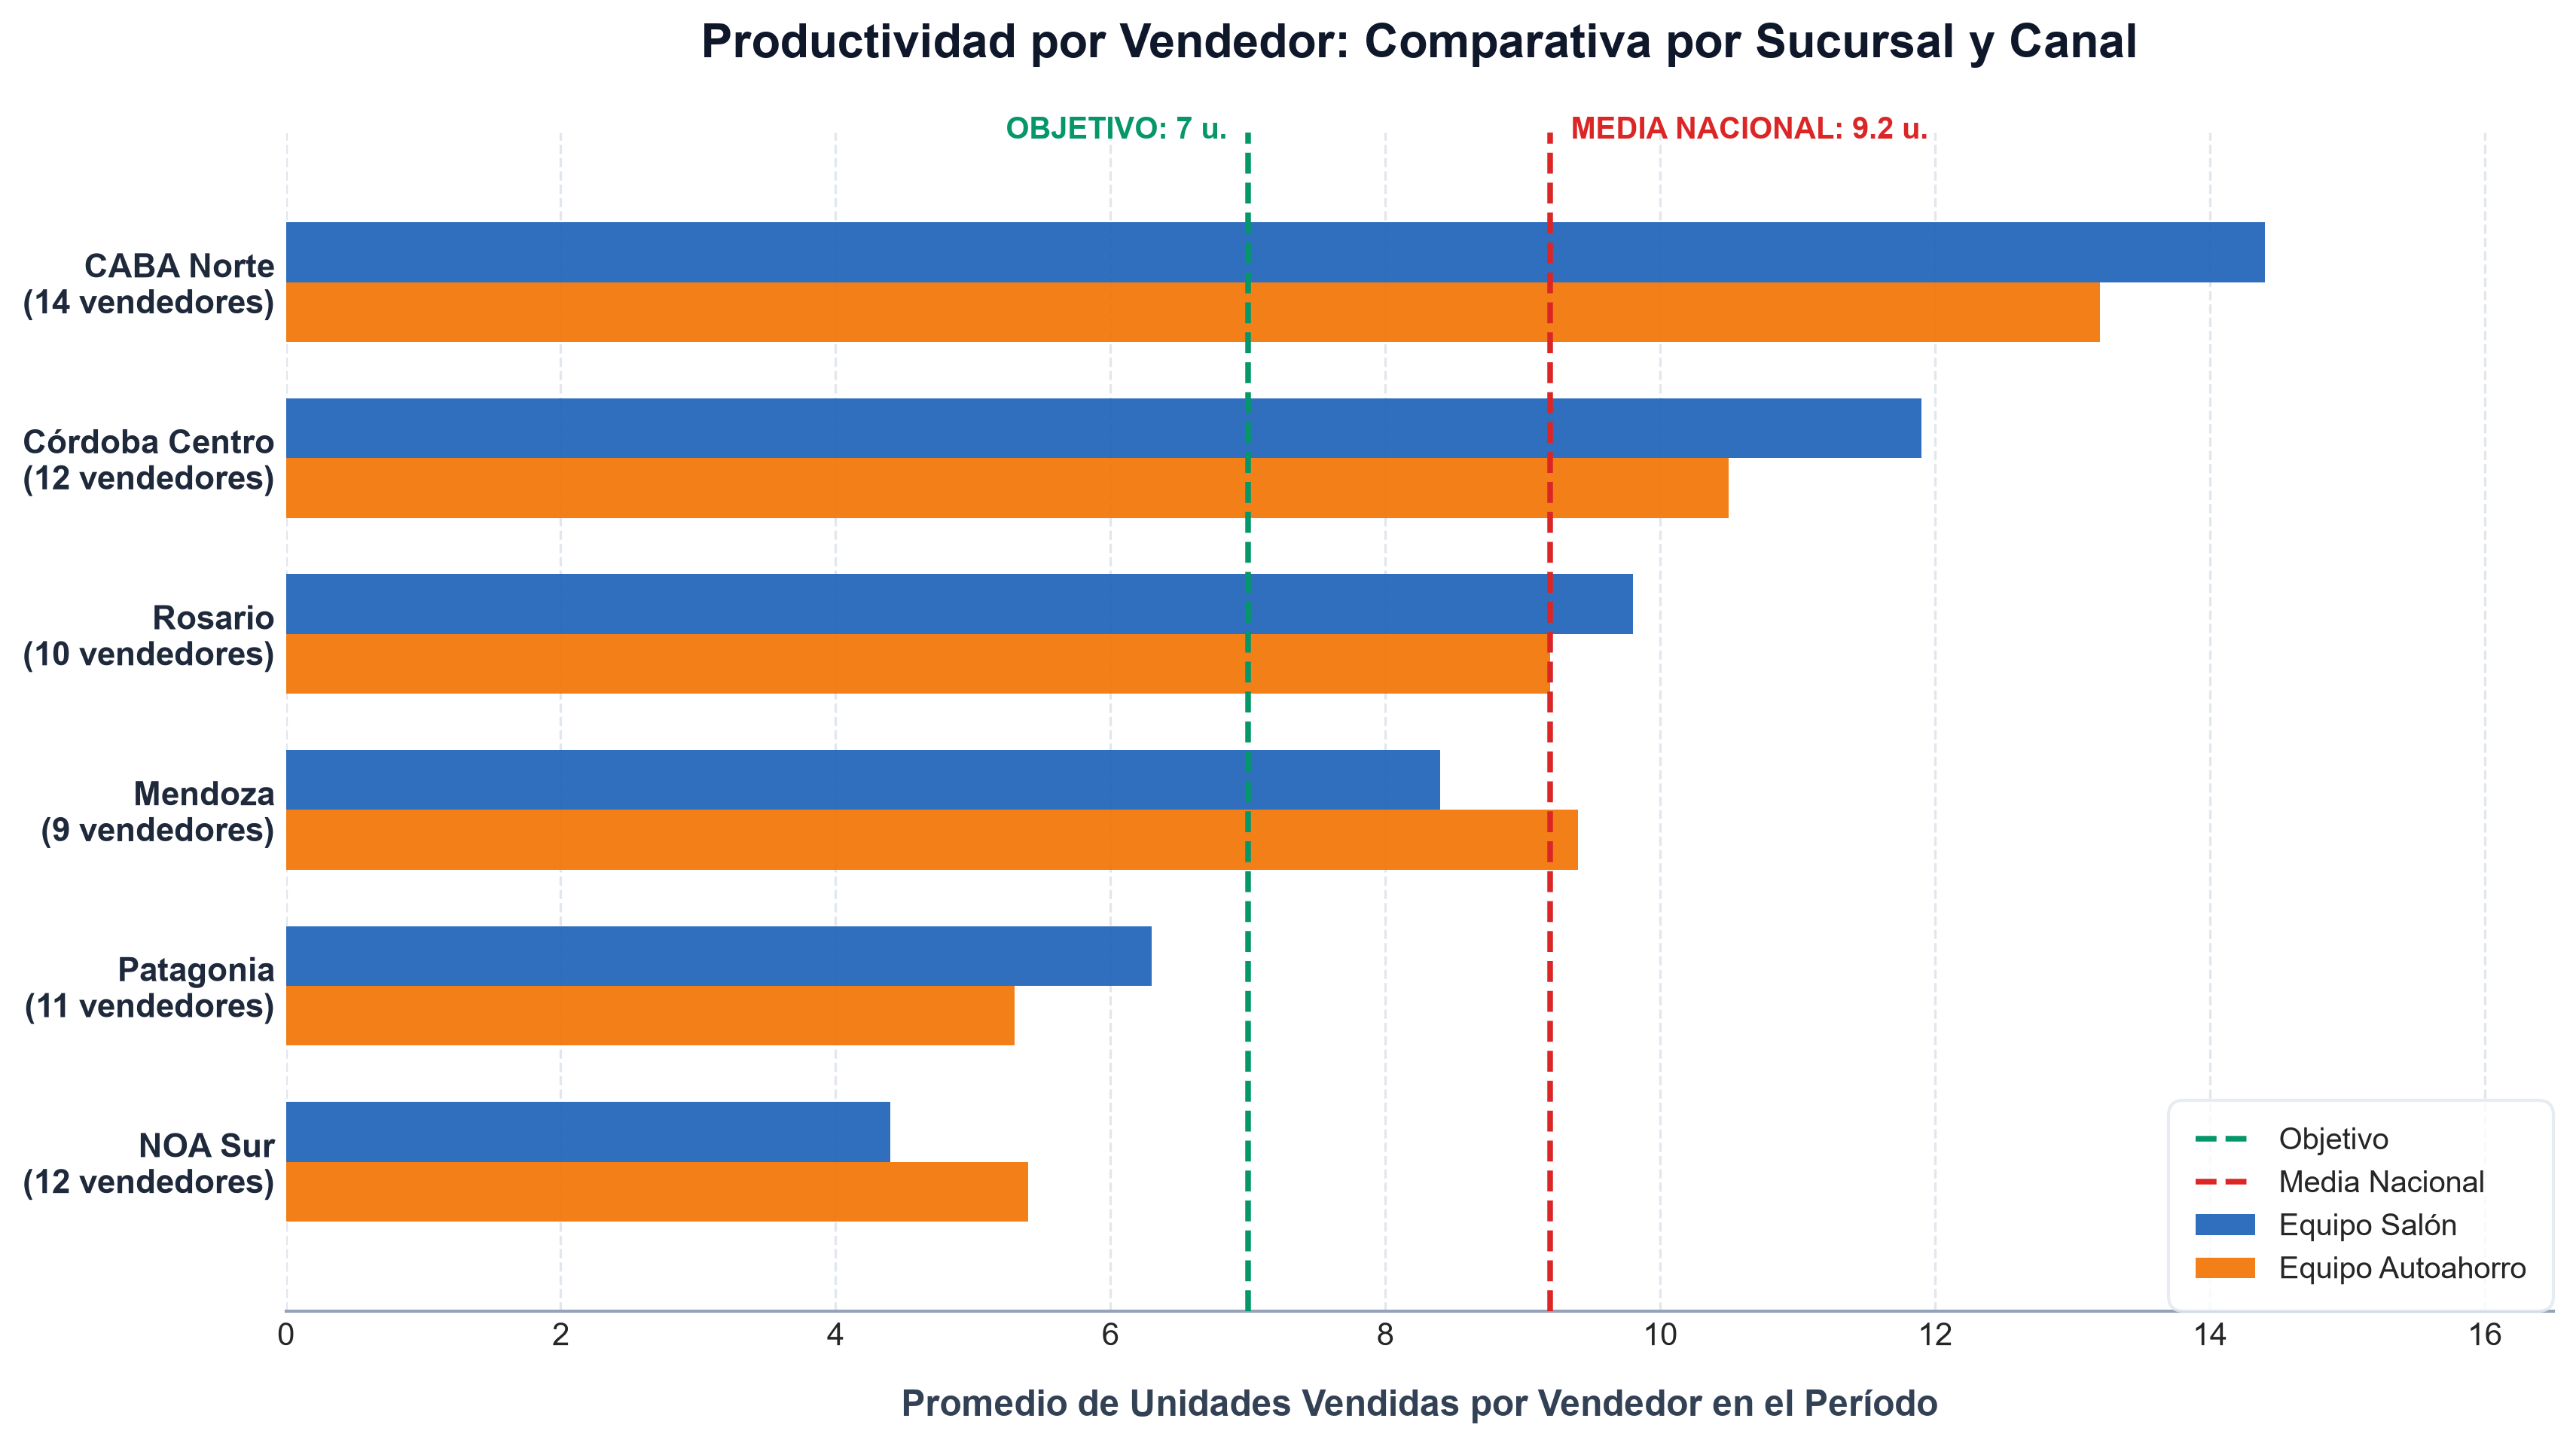

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

sucursales = ['CABA Norte', 'Córdoba Centro', 'Rosario', 'Mendoza', 'Patagonia', 'NOA Sur']
vendedores = [14, 12, 10, 9, 11, 12]

prod_salon = [14.4, 11.9, 9.8, 8.4, 6.3, 4.4]
prod_autoahorro = [13.2, 10.5, 9.2, 9.4, 5.3, 5.4]

objetivo_promedio = 7
media_nacional = 9.2

fig, ax = plt.subplots(figsize=(11.5, 6.5), dpi=300)

y = np.arange(len(sucursales))[::-1]
bar_height = 0.34

color_salon = '#1D63B8' # Azul 
color_autoahorro = '#F27405' # Naranja 

rects1 = ax.barh(y + bar_height/2, prod_salon, bar_height, 
                 label='Equipo Salón', color=color_salon, alpha=0.92, zorder=3)
rects2 = ax.barh(y - bar_height/2, prod_autoahorro, bar_height, 
                 label='Equipo Autoahorro', color=color_autoahorro, alpha=0.92, zorder=3)

# Línea de Objetivo 
ax.axvline(x=objetivo_promedio, color='#059669', linestyle='--', linewidth=1.8, zorder=4, 
           label=f'Objetivo')

# Línea de Media Nacional
ax.axvline(x=media_nacional, color='#DC2626', linestyle='--', linewidth=1.8, zorder=4, 
           label=f'Media Nacional')

ax.text(objetivo_promedio - 0.15, len(sucursales) - 0.22, f'OBJETIVO: {objetivo_promedio} u.', 
        color='#059669', fontsize=9.5, fontweight='bold', va='bottom', ha='right')

ax.text(media_nacional + 0.15, len(sucursales) - 0.22, f'MEDIA NACIONAL: {media_nacional:.1f} u.', 
        color='#DC2626', fontsize=9.5, fontweight='bold', va='bottom', ha='left')


etiquetas_eje_y = [f"{suc}\n({vend} vendedores)" for suc, vend in zip(sucursales, vendedores)]
ax.set_yticks(y)
ax.set_yticklabels(etiquetas_eje_y, fontsize=10.5, fontweight='bold', color='#1e293b')

ax.set_xlim(0, 16.5)
ax.set_ylim(-0.85, len(sucursales) - 0.15)

ax.set_title('Productividad por Vendedor: Comparativa por Sucursal y Canal', 
             fontsize=15, fontweight='bold', pad=24, color='#0f172a')
ax.set_xlabel('Promedio de Unidades Vendidas por Vendedor en el Período', 
              fontsize=11.5, fontweight='bold', labelpad=12, color='#334155')

ax.xaxis.grid(True, linestyle='--', alpha=0.55, color='#cbd5e1', zorder=0)
ax.yaxis.grid(False)

for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#94a3b8')

legend = ax.legend(loc='lower right', frameon=True, facecolor='#ffffff', 
                   edgecolor='#e2e8f0', fontsize=9.5)
legend.get_frame().set_boxstyle('round,pad=0.5')

plt.tight_layout()
plt.show()

**El gráfico muestra 3 situaciones**:
+ Hay una **gran disparidad** de ventas promedio entre las sucursales. El territorio puede dividirse en 2: las sucursales localizadas en las grandes ciudades, que tienen alta productividad superando el objetivo de 7 unidades promedio por vendedor (métrica arbitraria), y por el otro las regiones periféricas que no cumplen dicho objetivo.
+ Respecto de la baja productividad de las regiones NOA y Patagonia, al momento de cruzar los datos de ventas con la cantidad de empleados (todas las sucursarles tienen similar estructura) surgen inconsistencias graves en el dimensionamiento de los equipos, presentando algunos **indicios de personal excesivo** o subutilización de la fuerza de ventas.
+ En la mayoría de los casos la modalidad de Salón vende más que Autoahorro, el **único outlier** es la sucursal de Mendoza que, además de ser al revés, dicha métrica supera el promedio nacional.


## Conclusiones y llamados a acción

+ **Redimensionamiento de la fuerza de ventas en sucursales con baja productividad**: Reestructurar la dotación en NOA Sur (supongamos, de 12 a 8 vendedores) y en Patagonia (de 11 a 7). El impacto esperado es elevar el promedio individual de ventas por encima del umbral mínimo, reducir costos fijos de estructura y concentrar los leads en los perfiles de mayor tasa de conversión. 
+ **Estrategia de canal segmentada por región** (replicación del modelo de la sucursal de Mendoza): Dejar de aplicar directivas comerciales homogéneas para todo el país. En las plazas del interior, reasignar presupuestos de marketing y cupos de entrega para priorizar las suscripciones y licitaciones de Autoahorro. En plazas centrales, concentrar la venta de Salón en camionetas y modelos de alta gama.
+ **El "cuadrante vacío"** (Hibridación y Escala en Camionetas): Lanzar una campaña corporativa orientada a flotas y empresas para camionetas diésel y la introducción de versiones híbridas en el rango de 45-50k USD con el objetivo de escalar las ventas de camionetas de 980 a más de 1,200 unidades anuales, llevando la categoría a la zona ideal de Alto Volumen y Alto Valor. 
+ **Parametrización de objetivos**: Sustituir la meta plana de 7 unidades por vendedor por un esquema de métricas regionalizado. Implicaría elevar la exigencia en plazas maduras como CABA y Córdoba (donde la productividad ronda las 11 a 14 unidades) y recalibrar los objetivos de las demás en función del tamaño real de mercado y la cantidad de vendedores, ponderando las ventas por margen de contribución y no solo por unidades físicas. 